# GLCMaeV9 Training on Welding Robot Data

End-to-end training pipeline for `GLCMaeV9` — Asymmetric MAE with LogScaler + GlobalSeqNorm.

**V9 changes vs V8:**
- `LogScaler` + `GlobalSeqNorm` replace `GlobalRevIN` + `PerPatchRevIN`
- Both streams share the same pre-normalized input
- **No tail window** — only `range(0, T - seq_len + 1, stride)` windowing
- GlobalSeqNorm stats (`running_mean`/`running_var`) accumulate **automatically** via BatchNorm1d EMA during training loop — no explicit "fit" call needed
- Stats are saved in `model.state_dict()` via `seq_norm.bn.running_mean` / `running_var`
- Validation data: `val_train_welding_robot.csv` (normal only, full noise — realistic distribution)

**Pipeline:**
1. Load train CSV + val CSV → group by `cycle_id`, build codebooks
2. Create `RawWindowDataset` with robot/program indices
3. Initialize `GLCMaeV9` with context embedding
4. Train with `GLCMaeV8Trainer` (warmup + cosine LR, best-ckpt tracking)
5. Visualize training curves
6. Evaluate AUROC with synthetic anomaly injection
7. Save checkpoint

In [1]:
# %% Imports
import sys
import csv
import json
import math
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt

# Add project root to path
project_root = Path.cwd().parent.parent.resolve()
print(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from app.anomaly_detection.utils import set_random_seed
set_random_seed(42)

from app.anomaly_detection.models import create_model, SupportedAnomalyDetectionModels
from app.anomaly_detection.models.glc_mae_v9 import GLCMaeV9, GLCMaeV9Config
from app.anomaly_detection.training.glc_mae_v8_trainer import (
    GLCMaeV8Trainer,
    GLCMaeV8Evaluator,
)
from app.anomaly_detection.training.datasets import RawWindowDataset

print("All imports OK")
print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")

/home/trietlm/TED-Hackathon-Agent
All imports OK
PyTorch 2.12.0+cu130, CUDA available: True


## 1. Load Train + Validation Data

Two separate CSV files (generated by `Sprint20-Generate-Data.ipynb`).
- **Train** (`train_welding_robot.csv`): normal only, reduced noise, deterministic
- **Val** (`val_train_welding_robot.csv`): normal only, **full noise** (7 days)

**V9: No tail window.** Only `range(0, T - seq_len + 1, stride)` — for T=512, seq_len=256, stride=64 → 5 windows (no 6th zero-padded window).

In [2]:
DATA_DIR = project_root / "data" / "generated_sprint20"
TRAIN_CSV = DATA_DIR / "train_welding_robot.csv"
VAL_CSV   = DATA_DIR / "val_train_welding_robot.csv"

# Fallback to project_root/data/
if not TRAIN_CSV.exists():
    DATA_DIR = project_root / "data"
    TRAIN_CSV = DATA_DIR / "train_welding_robot.csv"
    VAL_CSV   = DATA_DIR / "val_train_welding_robot.csv"

print(f"Train CSV: {TRAIN_CSV}  (exists={TRAIN_CSV.exists()})")
print(f"Val CSV:   {VAL_CSV}  (exists={VAL_CSV.exists()})")

SENSOR_COLS = ["wire_feed_speed_mm_min", "wire_temperature_c", "welding_current_a"]
SEQ_LEN = 256
STRIDE  = 64
NUM_SENSORS = 3


def load_csv_to_windows(
    csv_path,
    seq_len=SEQ_LEN,
    stride=STRIDE,
    robot_to_idx=None,
    program_to_idx=None,
):
    """Load CSV -> group by cycle_id -> build macro-windows [N, C, T].

    V9: NO tail window. Only range(0, T - seq_len + 1, stride).
    For T=512, seq_len=256, stride=64: exactly 5 windows, no zero-padded 6th.

    If robot_to_idx / program_to_idx are provided, they are used as-is and
    extended for any unseen codes.  Pass them from a prior call to share the
    same vocabulary across train / val / test sets.
    """
    if not csv_path.exists():
        print(f"  WARNING: {csv_path} not found, returning empty.")
        empty = (
            np.zeros((0, NUM_SENSORS, seq_len), dtype=np.float32),
            np.zeros(0, dtype=np.int64),
            np.zeros(0, dtype=np.int64),
            robot_to_idx or {},
            program_to_idx or {},
        )
        return empty

    with open(csv_path, "r") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
    print(f"  Loaded {len(rows):,} rows from {csv_path.name}")

    groups = defaultdict(list)
    for r in rows:
        groups[int(r["cycle_id"])].append(r)
    print(f"  Unique cycle_ids: {len(groups)}")

    # Build or extend codebooks
    if robot_to_idx is None:
        all_robot_codes = sorted(set(str(r["robot_code"]) for r in rows))
        robot_to_idx = {code: i for i, code in enumerate(all_robot_codes)}
    else:
        for r in rows:
            rc = str(r["robot_code"])
            if rc not in robot_to_idx:
                robot_to_idx[rc] = len(robot_to_idx)

    if program_to_idx is None:
        all_program_nums = sorted(set(str(r["program_number"]) for r in rows))
        program_to_idx = {pn: i for i, pn in enumerate(all_program_nums)}
    else:
        for r in rows:
            pn = str(r["program_number"])
            if pn not in program_to_idx:
                program_to_idx[pn] = len(program_to_idx)

    windows_list, robot_list, program_list = [], [], []

    for cid, group_rows in groups.items():
        group_rows.sort(key=lambda x: int(x["serial_number"]))
        file_arr = np.array(
            [[float(r[col]) for col in SENSOR_COLS] for r in group_rows],
            dtype=np.float32,
        ).T  # [C, T]
        T = file_arr.shape[1]
        rc = str(group_rows[0]["robot_code"])
        pn = str(group_rows[0]["program_number"])

        if T >= seq_len:
            # V9: NO tail window — only regular stride windows
            for start in range(0, T - seq_len + 1, stride):
                windows_list.append(file_arr[:, start:start + seq_len])
                robot_list.append(robot_to_idx[rc])
                program_list.append(program_to_idx[pn])
            # NO tail padding (removed in V9)
        else:
            pad = np.zeros((NUM_SENSORS, seq_len - T), dtype=np.float32)
            windows_list.append(np.hstack([file_arr, pad]))
            robot_list.append(robot_to_idx[rc])
            program_list.append(program_to_idx[pn])

    windows_arr = np.stack(windows_list, axis=0)   # [N, C, T]
    robot_arr   = np.array(robot_list,   dtype=np.int64)
    program_arr = np.array(program_list, dtype=np.int64)

    assert len(windows_arr) == len(robot_arr) == len(program_arr), (
        f"Length mismatch: windows={len(windows_arr)}, "
        f"robot={len(robot_arr)}, program={len(program_arr)}"
    )
    print(f"  Windows: {windows_arr.shape}")
    return windows_arr, robot_arr, program_arr, robot_to_idx, program_to_idx

print("\n--- Loading TRAIN data ---")
(
    train_windows, train_robots, train_programs,
    robot_to_idx, program_to_idx,
) = load_csv_to_windows(TRAIN_CSV)

print("\n--- Loading VALIDATION data ---")
(
    val_windows, val_robots, val_programs,
    robot_to_idx, program_to_idx,
) = load_csv_to_windows(VAL_CSV, robot_to_idx=robot_to_idx, program_to_idx=program_to_idx)

NUM_ROBOTS   = len(robot_to_idx)
NUM_PROGRAMS = len(program_to_idx)

print(f"\nCombined codebooks: {NUM_ROBOTS} robots, {NUM_PROGRAMS} programs")
print(f"Train windows: {len(train_windows)}, Val windows: {len(val_windows)}")

Train CSV: /home/trietlm/TED-Hackathon-Agent/data/generated_sprint20/train_welding_robot.csv  (exists=True)
Val CSV:   /home/trietlm/TED-Hackathon-Agent/data/generated_sprint20/val_train_welding_robot.csv  (exists=True)

--- Loading TRAIN data ---
  Loaded 32,769,024 rows from train_welding_robot.csv
  Unique cycle_ids: 64002
  Windows: (320010, 3, 256)

--- Loading VALIDATION data ---
  Loaded 8,139,264 rows from val_train_welding_robot.csv
  Unique cycle_ids: 15897
  Windows: (79485, 3, 256)

Combined codebooks: 4 robots, 16 programs
Train windows: 320010, Val windows: 79485


## 2. Create Dataset & DataLoader

In [3]:
BATCH_SIZE = 64

train_dataset = RawWindowDataset(
    windows=train_windows,
    robot_indices=train_robots,
    program_indices=train_programs,
)
val_dataset = RawWindowDataset(
    windows=val_windows,
    robot_indices=val_robots,
    program_indices=val_programs,
)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
    num_workers=0, pin_memory=False,
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=False,
)

print(f"Train windows:  {len(train_dataset)}")
print(f"Val windows:    {len(val_dataset)}")
print(f"Batches/epoch:  train={len(train_loader)}, val={len(val_loader)}")
print(f"Sample keys:    {list(train_dataset[0].keys())}")
print(f"  input shape:  {train_dataset[0]['input'].shape}")
print(f"  robot_idx:    {train_dataset[0]['robot_idx'].item()}")
print(f"  program_idx:  {train_dataset[0]['program_idx'].item()}")

Train windows:  320010
Val windows:    79485
Batches/epoch:  train=5000, val=1242
Sample keys:    ['input', 'robot_idx', 'program_idx']
  input shape:  torch.Size([3, 256])
  robot_idx:    0
  program_idx:  14


## 3. Initialize GLCMaeV9 Model

Key config:
- `LogScaler` + `GlobalSeqNorm` (replaces `GlobalRevIN` + `PerPatchRevIN`)
- `num_sensors=3`, `seq_len=256`
- `num_robots` / `num_programs` from loaded codebooks → enables `ContextEmbedding`
- `mask_ratio=0.45` → 45% of tokens masked during training
- `patch_size=32`, `patch_stride=16` → 15 patches per sensor with seq_len=256

**Running stats note:** `GlobalSeqNorm` uses `nn.BatchNorm1d` with `track_running_stats=True`.
During `model.train()`, `running_mean` / `running_var` accumulate automatically via EMA
on every forward pass. Stats are saved in `model.state_dict()`. No explicit "fit" call needed.

In [5]:
config = GLCMaeV9Config(
    num_sensors=NUM_SENSORS,
    seq_len=SEQ_LEN,
    num_robots=8,
    num_programs=128,
    patch_size=32,
    patch_stride=16,
    d_model=128,
    transformer_layers=4,
    transformer_heads=4,
    ffn_dim=512,
    dropout=0.2,
    mask_ratio=0.4,
    use_context_embeddings=True,
)

model = create_model(SupportedAnomalyDetectionModels.GLC_MAE_V9, config)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model:           {model.name}")
print(f"Total params:    {total_params:,}")
print(f"Trainable:       {trainable_params:,}")
print(f"num_patches:     {model.num_patches}  (per sensor)")
print(f"num_tokens:      {model.num_tokens}  (C * P = {NUM_SENSORS} * {model.num_patches})")
print(f"mask_ratio:      {model.mask_ratio}")
print(f"normalizer:      {model.get_metadata()['normalizer']}")
print(f"\nGlobalSeqNorm stats accumulate automatically during training")
print(f"  → seq_norm.bn.running_mean: {model.seq_norm.bn.running_mean.shape}")
print(f"  → seq_norm.bn.running_var:  {model.seq_norm.bn.running_var.shape}")

Model:           GLCMaeV9
Total params:    966,743
Trainable:       966,743
num_patches:     15  (per sensor)
num_tokens:      45  (C * P = 3 * 15)
mask_ratio:      0.4
normalizer:      log+global_seq_norm

GlobalSeqNorm stats accumulate automatically during training
  → seq_norm.bn.running_mean: torch.Size([3])
  → seq_norm.bn.running_var:  torch.Size([3])


## 4. Smoke Test — Forward Pass

Verify forward pass and loss computation before full training.

In [6]:
model.eval()
with torch.no_grad():
    dummy_batch = {
        "input":       torch.randn(2, NUM_SENSORS, SEQ_LEN),
        "robot_idx":   torch.zeros(2, dtype=torch.long),
        "program_idx": torch.zeros(2, dtype=torch.long),
    }
    out = model.compute_loss(dummy_batch)
    heatmap = model.compute_heatmap(dummy_batch)

print(f"Smoke test PASSED")
print(f"  loss:    {out['loss'].item():.6f}  (scalar)")
print(f"  recon_error shape: {out['recon_error'].shape}  (expected [2, {model.num_tokens}])")
print(f"  heatmap shape:     {heatmap.shape}  (expected [2, {NUM_SENSORS}, {model.num_patches}])")

Smoke test PASSED
  loss:    0.408281  (scalar)
  recon_error shape: torch.Size([2, 45])  (expected [2, 45])
  heatmap shape:     torch.Size([2, 3, 15])  (expected [2, 3, 15])


## 5. Initialize Trainer & Train

- Uses `GLCMaeV8Trainer` (compatible — same `compute_loss` / `compute_anomaly_score` interface)
- Linear warmup for first 25 epochs, then CosineAnnealing to `lr * 0.01`
- **Both train and val loss use the masked MAE forward** → no distribution mismatch
- Best checkpoint (lowest val_loss) stored automatically in `trainer.best_state_dict`
- GlobalSeqNorm `running_mean`/`running_var` accumulate automatically during training

In [7]:
EPOCHS        = 100
LR            = 1e-3
WARMUP_EPOCHS = 25

trainer = GLCMaeV8Trainer(
    model=model,
    lr=LR,
    weight_decay=1e-5,
    clip_grad_norm=1.0,
    warmup_epochs=WARMUP_EPOCHS,
    total_epochs=EPOCHS,
    min_lr_ratio=0.01,
)

print(f"Device:      {trainer.device}")
print(f"Epochs:      {EPOCHS}  (warmup={WARMUP_EPOCHS}, cosine={EPOCHS - WARMUP_EPOCHS})")
print(f"LR:          {LR:.1e} → {LR * 0.01:.1e}  (peak → floor)")
print("GlobalSeqNorm stats (running_mean/running_var) accumulate automatically during training.")
print("They are saved as part of model.state_dict() when checkpointing.")
print("\nStarting training...")

history = trainer.train(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    lr=LR,
    save_best=True,
)

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)
print(f"  train_loss:  {history['loss'][0]:.4f} → {history['loss'][-1]:.4f}")
print(f"  val_loss:    {history['val_loss'][0]:.4f} → {history['val_loss'][-1]:.4f}")
print(f"  best epoch:  {trainer.best_epoch + 1}  (val_loss={trainer.best_val_loss:.4f})")
print("=" * 60)

Device:      cuda
Epochs:      100  (warmup=25, cosine=75)
LR:          1.0e-03 → 1.0e-05  (peak → floor)
GlobalSeqNorm stats (running_mean/running_var) accumulate automatically during training.
They are saved as part of model.state_dict() when checkpointing.

Starting training...


Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Train E1:   0%|          | 0/5000 [00:00<?, ?it/s]

Val:   0%|          | 0/1242 [00:00<?, ?it/s]

Train E2:   0%|          | 0/5000 [00:00<?, ?it/s]

...

Train E99:   0%|          | 0/5000 [00:00<?, ?it/s]

Val:   0%|          | 0/1242 [00:00<?, ?it/s]

Train E100:   0%|          | 0/5000 [00:00<?, ?it/s]

Val:   0%|          | 0/1242 [00:00<?, ?it/s]


TRAINING COMPLETE
  train_loss:  0.3694 → 0.1094
  val_loss:    0.3912 → 0.1463
  best epoch:  69  (val_loss=0.1431)


## 6. Visualize Training Curves

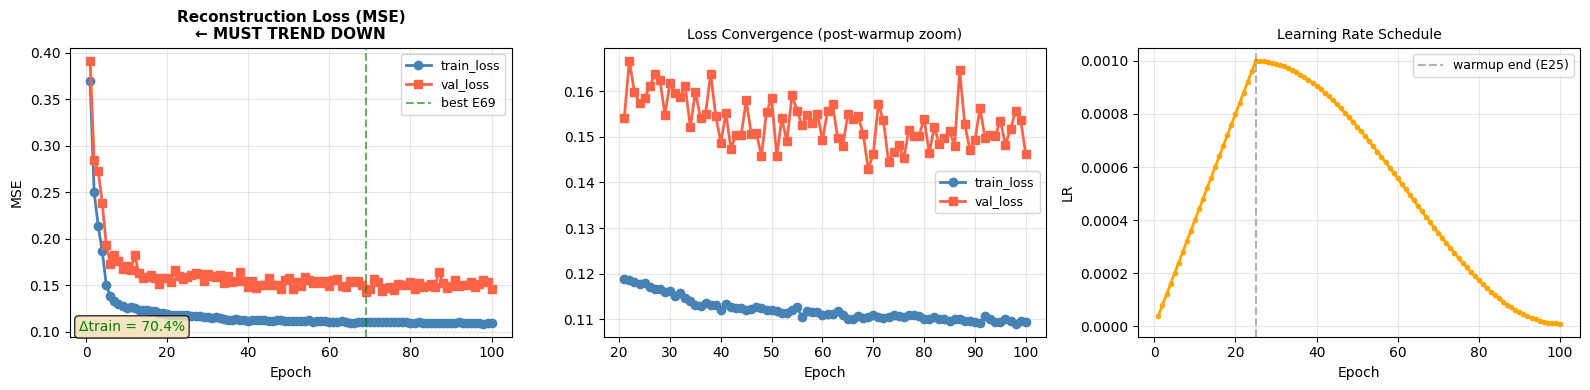

TRAINING HEALTH REPORT
  train_loss:  0.3694 → 0.1094  (+70.4%)
  val_loss:    0.3912 → 0.1463
  gap (val-train): 0.0368  (near 0 = no mismatch)
  best epoch:  69  val=0.1431


In [8]:
epochs_range = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (0): train vs val loss
ax = axes[0]
ax.plot(epochs_range, history["loss"],     marker="o", lw=2, color="steelblue", label="train_loss")
ax.plot(epochs_range, history["val_loss"], marker="s", lw=2, color="tomato",    label="val_loss")
ax.axvline(x=trainer.best_epoch + 1, color="green", ls="--", alpha=0.6,
           label=f"best E{trainer.best_epoch + 1}")
improvement = (history["loss"][0] - history["loss"][-1]) / max(history["loss"][0], 1e-8) * 100
ax.text(0.02, 0.02, f"Δtrain = {improvement:.1f}%", transform=ax.transAxes,
        fontsize=10, color="green" if improvement > 5 else "red",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))
ax.set_title("Reconstruction Loss (MSE)\n← MUST TREND DOWN", fontsize=11, fontweight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# (1): train vs val loss zoom (last 80%)
ax = axes[1]
start_ep = max(0, len(history["loss"]) // 5)
ax.plot(list(epochs_range)[start_ep:], history["loss"][start_ep:],
        marker="o", lw=2, color="steelblue", label="train_loss")
ax.plot(list(epochs_range)[start_ep:], history["val_loss"][start_ep:],
        marker="s", lw=2, color="tomato",    label="val_loss")
ax.set_title("Loss Convergence (post-warmup zoom)", fontsize=10)
ax.set_xlabel("Epoch"); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# (2): LR schedule
ax = axes[2]
ax.plot(epochs_range, history["lr"], marker=".", color="orange", lw=2)
ax.axvline(x=WARMUP_EPOCHS, color="gray", ls="--", alpha=0.6, label=f"warmup end (E{WARMUP_EPOCHS})")
ax.set_title("Learning Rate Schedule", fontsize=10)
ax.set_xlabel("Epoch"); ax.set_ylabel("LR")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 55)
print("TRAINING HEALTH REPORT")
print("=" * 55)
gap = history["val_loss"][-1] - history["loss"][-1]
print(f"  train_loss:  {history['loss'][0]:.4f} → {history['loss'][-1]:.4f}  ({improvement:+.1f}%)")
print(f"  val_loss:    {history['val_loss'][0]:.4f} → {history['val_loss'][-1]:.4f}")
print(f"  gap (val-train): {gap:.4f}  (near 0 = no mismatch)")
print(f"  best epoch:  {trainer.best_epoch + 1}  val={trainer.best_val_loss:.4f}")
print("=" * 55)

## 7. Restore Best Checkpoint & Save Model

Restore best weights, verify stats are preserved, and save checkpoint.

In [9]:
# Restore best weights
trainer.restore_best()
print(f"Restored best checkpoint from epoch {trainer.best_epoch + 1}")

# Verify GlobalSeqNorm stats are preserved
print(f"\nGlobalSeqNorm stats after restore:")
print(f"  running_mean: {model.seq_norm.bn.running_mean}")
print(f"  running_var:  {model.seq_norm.bn.running_var[:3]}... (showing first 3)")

# Save checkpoint with metadata
import os
checkpoint_dir = project_root / "checkpoints" / "glc_mae_v9"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint = {
    "model_state_dict": trainer.best_state_dict,
    "metadata": model.get_metadata(),
    "config": config.to_dict(),
    "val_loss": trainer.best_val_loss,
    "epoch": trainer.best_epoch,
    "robot_to_idx": robot_to_idx,
    "program_to_idx": program_to_idx,
}

ckpt_path = checkpoint_dir / "best_glc_mae_v9.pt"
torch.save(checkpoint, ckpt_path)
print(f"\nCheckpoint saved to: {ckpt_path}")
print(f"  File size: {os.path.getsize(ckpt_path) / 1024 / 1024:.1f} MB")
print(f"  Includes GlobalSeqNorm running stats in model_state_dict")

Restored best checkpoint from epoch 69

GlobalSeqNorm stats after restore:
  running_mean: tensor([5.2280, 3.5733, 2.6878], device='cuda:0')
  running_var:  tensor([1.1286, 0.0085, 0.0496], device='cuda:0')... (showing first 3)

Checkpoint saved to: /home/trietlm/TED-Hackathon-Agent/checkpoints/glc_mae_v9/best_glc_mae_v9.pt
  File size: 3.7 MB
  Includes GlobalSeqNorm running stats in model_state_dict
